<a href="https://colab.research.google.com/github/Fata-Haidar/PCVK_Ganjil_2026/blob/main/pertemuan9/week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1. Tautkan dengan Google Drive**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**2. Import Library**

In [2]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

**3. fungsi dilasi serta tampilkan hasil dilasi pada citra dengan Structuring Element
Dilasi (SED) berbentuk cross 3 x 3 tanpa menggunakan library morphology dari
openCV**

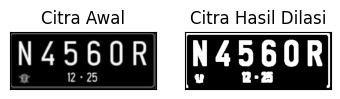

In [14]:

#Dilasi tanpa library
def dilasi_citra(F,w):
    #size image
    p,q= F.shape
    imgD= np.zeros((p,q), dtype=np.uint8)

    #Generate structure element dilasi (SED)
    SED= np.ones((w,w), dtype=np.uint8)
    constant1= (w-1)//2

    #Proses Dilasi
    for i in range(constant1, p-constant1):
        for j in range(constant1,q-constant1):
            temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product= temp*SED
            imgD[i,j]= np.max(product)
    return imgD

img_d= cv2.imread('/content/drive/MyDrive/PCVK/plat_nomer1.png',0)
ret, thresh = cv2.threshold(img_d, 125, 200, cv2.THRESH_BINARY)
w=5
imgD = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()


**4. implementasi operasi dilasi Structuring Element Dilasi (SED)
berbentuk cross 3 x 3 dengan menggunakan library morphology dari openCV**

[[1 1 1]
 [1 1 1]
 [1 1 1]]


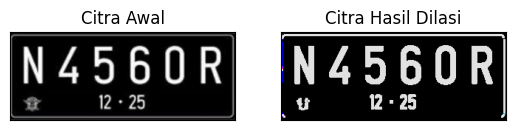

In [15]:
img = cv2.imread('/content/drive/MyDrive/PCVK/plat_nomer1.png')
#img = cv2.imread('morp.jpg',0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint16)
dilasi = cv2.dilate(thresh,kernel,iterations = 1)
print(kernel)
plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(dilasi),plt.title('Citra Hasil Dilasi')
plt.xticks([]), plt.yticks([])
plt.show()

**5. fungsi erosi sertaserta tampilkan hasil erosi pada citra dengan Structuring Element
Erosi (SE) berbentuk square 5 x 5 tanpa menggunakan library morphology dari
openCV**

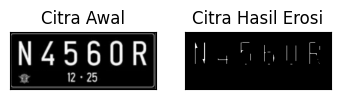

In [16]:

#Erosi Tanpa Library
def erosi_citra(F,k):
    #size image
    m,n= F.shape

    #Generate structure element erosi (SE)
    SE= np.ones((k,k), dtype=np.uint8)
    constant= (k-1)//2
    imgE= np.zeros((m,n), dtype=np.uint8)

    #Proses Erosi
    for i in range(constant, m-constant):
        for j in range(constant,n-constant):
            temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
            product= temp*SE
            imgE[i,j]= np.min(product)
    return imgE

img_e= cv2.imread('/content/drive/MyDrive/PCVK/plat_nomer1.png',0) #
ret1, thresh1 = cv2.threshold(img_e, 175, 225, cv2.THRESH_BINARY)
k=5
imgE = erosi_citra(thresh1,k)

plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()


**6. implementasi operasi dilasi Structuring Element Erosi (SE) berbentuk
square 5 x 5 dengan menggunakan library morphology dari openCV**

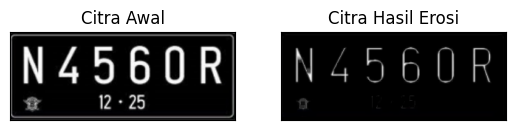

In [17]:

#EROSI LIBRARY
img = cv2.imread('/content/drive/MyDrive/PCVK/plat_nomer1.png')
kernel = np.ones((5,5),np.uint8)
erosion = cv2.erode(img,kernel,iterations = 1)
plt.subplot(121),plt.imshow(img),plt.title('Citra Awal')
plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(erosion),plt.title('Citra Hasil Erosi')
plt.xticks([]), plt.yticks([])
plt.show()


**7. implementasi operasi opening dengan Structuring Element berbentuk
square 3 x 3 tanpa dan dengan menggunakan library morphology dari openCV**

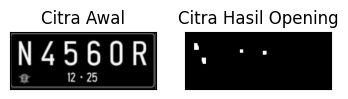

In [18]:
img_o= cv2.imread('/content/drive/MyDrive/PCVK/plat_nomer1.png',0) #
reto, thresho = cv2.threshold(img_o, 127, 225, cv2.THRESH_BINARY)
k=7
imgO = dilasi_citra(erosi_citra(thresho,k),k)
plt.subplot(131),plt.imshow(img_o,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgO,cmap = 'gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

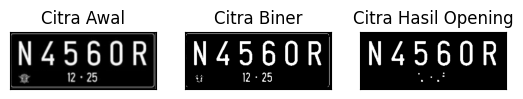

In [19]:
#Dengan Menggunakan Library
img = cv2.imread('/content/drive/MyDrive/PCVK/plat_nomer1.png',0)
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint8)
openn = cv2.morphologyEx(thresh,cv2.MORPH_OPEN, kernel)
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133),plt.imshow(openn,cmap = 'gray')
plt.title('Citra Hasil Opening'), plt.xticks([]), plt.yticks([])
plt.show()

**8. implementasi operasi closing dengan Structuring Element berbentuk
square 3 x 3 tanpa dan dengan menggunakan library morphology dari openCV**

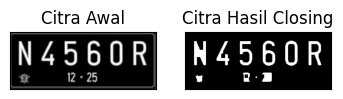

In [20]:
img_c= cv2.imread('/content/drive/MyDrive/PCVK/plat_nomer1.png',0) #
retc, threshc = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
k=7
imgC = erosi_citra(dilasi_citra(threshc,k),k)
plt.subplot(131),plt.imshow(img_c,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgC,cmap = 'gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

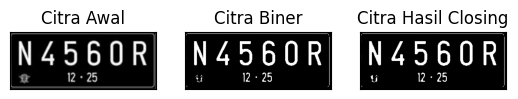

In [21]:
img_c= cv2.imread('/content/drive/MyDrive/PCVK/plat_nomer1.png',0) #
ret, thresh = cv2.threshold(img, 127, 225, cv2.THRESH_BINARY)
kernel = np.ones((3,3),np.uint8)
closs = cv2.morphologyEx(thresh,cv2.MORPH_CLOSE, kernel)
plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(thresh,cmap = 'gray')
plt.title('Citra Biner'), plt.xticks([]), plt.yticks([])
plt.subplot(133),plt.imshow(closs,cmap = 'gray')
plt.title('Citra Hasil Closing'), plt.xticks([]), plt.yticks([])
plt.show()

**9. implementasi operasi dilasi dengan Structuring Element berbentuk
Cross 3 x 3 dan 5 x 5**

SED = Cross 3


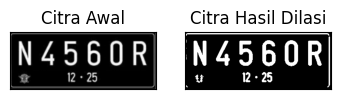

SED = Cross 5


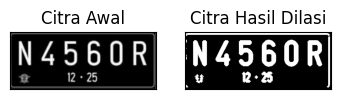

In [25]:

#Dilasi Cross SED
def dilasi_citra(F,w):
    #size image
    p,q= F.shape
    imgD= np.zeros((p,q), dtype=np.uint8)

    #Generate structure element dilasi (SED)
    # SED= np.ones((w,w), dtype=np.uint8)
    SED = np.array([[0, 1, 0],
                    [1, 1, 1],
                    [0, 1, 0]], dtype = np.uint8)
    constant1= (w-1)//2

    #Proses Dilasi
    for i in range(constant1, p-constant1):
        for j in range(constant1,q-constant1):
            temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product= temp*SED
            imgD[i,j]= np.max(product)
    return imgD

print('SED = Cross 3')
img_c= cv2.imread('/content/drive/MyDrive/PCVK/plat_nomer1.png',0) #
ret, thresh = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
w=3
imgD = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_c,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()


def dilasi_citra(F,w):
    #size image
    p,q= F.shape
    imgD= np.zeros((p,q), dtype=np.uint8)

    #Generate structure element dilasi (SED)
    # SED= np.ones((w,w), dtype=np.uint8)
    SED = np.array([[0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0],
                    [1, 1, 1, 1, 1],
                    [0, 0, 1, 0, 0],
                    [0, 0, 1, 0, 0]], dtype = np.uint8)
    constant1= (w-1)//2

    #Proses Dilasi
    for i in range(constant1, p-constant1):
        for j in range(constant1,q-constant1):
            temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product= temp*SED
            imgD[i,j]= np.max(product)
    return imgD

print('SED = Cross 5')
img_c= cv2.imread('/content/drive/MyDrive/PCVK/plat_nomer1.png',0) #
ret, thresh = cv2.threshold(img_c, 127, 225, cv2.THRESH_BINARY)
w=5
imgD = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_c,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()


**10. program implementasi operasi dilasi dengan Structuring Element berbentuk
Circular 3 x 3 dan 5 x 5**

SED = Circle 3


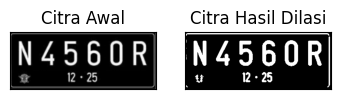

SED = Circle 5


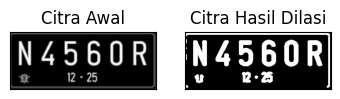

In [26]:

#Dilasi Circular SED
def dilasi_citra(F,w):
    #size image
    p,q= F.shape
    imgD= np.zeros((p,q), dtype=np.uint8)

    #Generate structure element dilasi (SED)
    SED= cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(w,w))
    constant1= (w-1)//2

    #Proses Dilasi
    for i in range(constant1, p-constant1):
        for j in range(constant1,q-constant1):
            temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
            product= temp*SED
            imgD[i,j]= np.max(product)
    return imgD

print('SED = Circle 3')
img_d= cv2.imread('/content/drive/MyDrive/PCVK/plat_nomer1.png',0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w=3
imgD = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()

print('SED = Circle 5')
img_d= cv2.imread('/content/drive/MyDrive/PCVK/plat_nomer1.png',0)
ret, thresh = cv2.threshold(img_d, 127, 225, cv2.THRESH_BINARY)
w=5
imgD = dilasi_citra(thresh,w)

plt.subplot(131),plt.imshow(img_d,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgD,cmap = 'gray')
plt.title('Citra Hasil Dilasi'), plt.xticks([]), plt.yticks([])
plt.show()


**11. program implementasi operasi erosi dengan Structuring Element berbentuk
Rectangle 3 x 5 dan 5 x 7**

SE = Rectangle 3x5


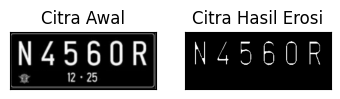

SE = Rectangle 5x7


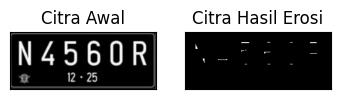

In [27]:

#Erosi Cross SE
def erosi_citra(F,p,l):
    #size image
    m,n= F.shape

    #Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_RECT,(p,l)) #SE persegi panjang
    constant1= (l-1)//2
    constant2= (p-1)//2
    # print(SE)
    imgE= np.zeros((m,n), dtype=np.uint8)

    #Proses Erosi
    for i in range(constant1, m-constant1):
        for j in range(constant2,n-constant2):
            temp= F[i-constant1:i+constant1+1, j-constant2:j+constant2+1]
            product= temp*SE
            imgE[i,j]= np.min(product)
    return imgE

print('SE = Rectangle 3x5')
img_e= cv2.imread('/content/drive/MyDrive/PCVK/plat_nomer1.png',0) #
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p=5
l=3
imgE = erosi_citra(thresh1,p,l)

plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

print('SE = Rectangle 5x7')
img_e= cv2.imread('/content/drive/MyDrive/PCVK/plat_nomer1.png',0) #
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
p=7
l=5
imgE = erosi_citra(thresh1,p,l)

plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()


**12. program implementasi operasi erosi dengan Structuring Element berbentuk
Line Vertikal 3 dan 5**

SE = Line Vertikal 3


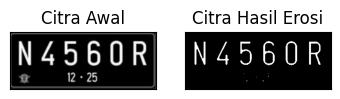

SE = Line Vertikal 5


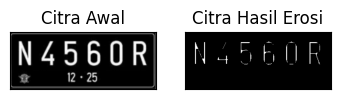

In [28]:

#Erosi Line Vertikal SE
def erosi_citra(F,k):
    #size image
    m,n= F.shape

    #Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(1,k)) #SE line vertikal
    constant= (k-1)//2
    imgE= np.zeros((m,n), dtype=np.uint8)

    #Proses Erosi
    for i in range(constant, m-constant):
        for j in range(constant,n-constant):
            temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
            product= temp*SE
            imgE[i,j]= np.min(product)
    return imgE

print('SE = Line Vertikal 3')
img_e= cv2.imread('/content/drive/MyDrive/PCVK/plat_nomer1.png',0) #
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k=3
imgE = erosi_citra(thresh1,k)

plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()

print('SE = Line Vertikal 5')
img_e= cv2.imread('/content/drive/MyDrive/PCVK/plat_nomer1.png',0) #
ret1, thresh1 = cv2.threshold(img_e, 127, 225, cv2.THRESH_BINARY)
k=5
imgE = erosi_citra(thresh1,k)

plt.subplot(131),plt.imshow(img_e,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(imgE,cmap = 'gray')
plt.title('Citra Hasil Erosi'), plt.xticks([]), plt.yticks([])
plt.show()


**13 TopHat**

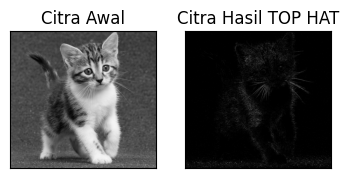

In [31]:

# Getting the kernel to be used in Top-Hat
filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT,
                                   filterSize)

# Reading the image named 'input.jpg'
img = cv2.imread('/content/drive/MyDrive/PCVK/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Top-Hat operation
tophat_img = cv2.morphologyEx(img,
                              cv2.MORPH_TOPHAT,
                              kernel)

#cv2.imshow("original", img)
#cv2.imshow("tophat", tophat_img)
#cv2.waitKey(5000)

plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(tophat_img,cmap = 'gray')
plt.title('Citra Hasil TOP HAT'), plt.xticks([]), plt.yticks([])
plt.show()


**14 BLACKHAT**

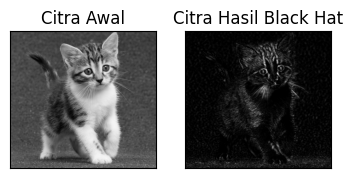

In [33]:

filterSize =(3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, filterSize)

# Reading the image named 'input.jpg'
img = cv2.imread('/content/drive/MyDrive/PCVK/kitten01.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applying the Black-Hat operation
#tophat_img = cv2.morphologyEx(img,cv2.MORPH_BLACKHAT, kernel)
Kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (13, 5))
blackhat = cv2.morphologyEx(img, cv2.MORPH_BLACKHAT, Kernel)

#cv2.imshow("original", input_image)
#cv2.imshow("tophat", tophat_img)
#cv2.waitKey(5000)

plt.subplot(131),plt.imshow(img,cmap = 'gray')
plt.title('Citra Awal'), plt.xticks([]), plt.yticks([])
plt.subplot(132),plt.imshow(blackhat,cmap = 'gray')
plt.title('Citra Hasil Black Hat'), plt.xticks([]), plt.yticks([])
plt.show()


**15. Skeleton**

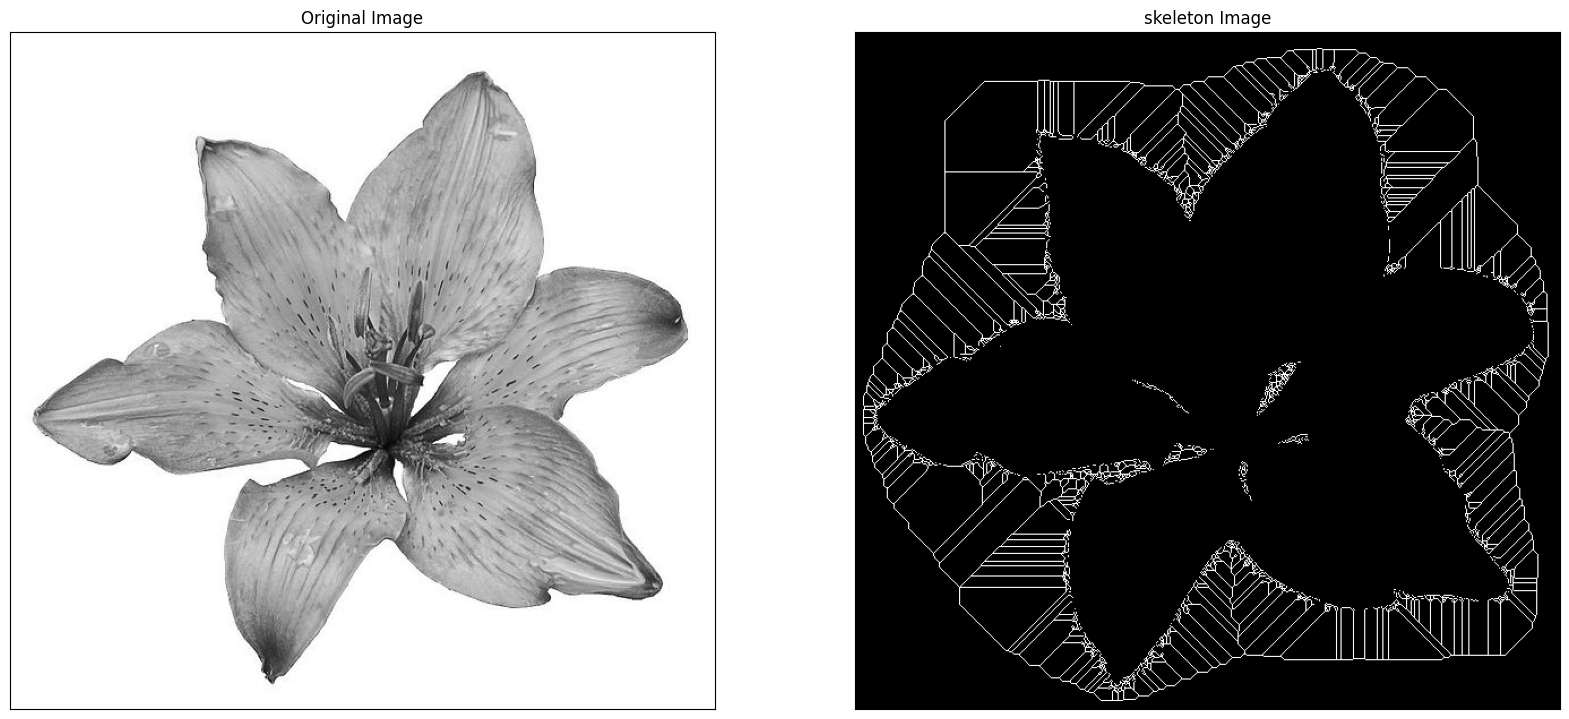

In [34]:

import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

# read image
img = cv.imread('/content/drive/MyDrive/PCVK/lily.jpg',0)
binary = img > filters.threshold_triangle(img)

# true false to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# skeletonize image
skeleton = skeletonize(binary_cp)

# print images
plt.figure(figsize=(20,20))
plt.subplot(121),plt.imshow(img,cmap = 'gray')
plt.title('Original Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(skeleton,cmap = 'gray')
plt.title('skeleton Image'), plt.xticks([]), plt.yticks([])
plt.savefig("binary and bin_skeleton.png")
plt.show()


**16. Skeleton Inverse**

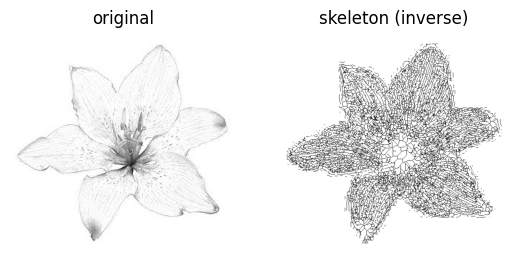

In [35]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize
# read image
img = io.imread('/content/drive/MyDrive/PCVK/lily.jpg')[..., 0]
# Note: we want the black bits to be True, so use <
binary = img < filters.threshold_triangle(img)
# skeletonize image
skeleton = skeletonize(binary)
# print images
fig, ax = plt.subplots(1, 2)
ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()
# note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()
plt.show()

**17. Thickening**

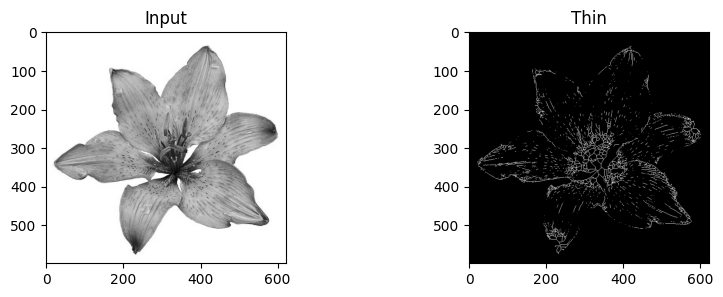

In [37]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt
image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/PCVK/lily.jpg')))
image_binary = image < 0.5
out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

f, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 3))
ax0.imshow(image, cmap='gray')
ax0.set_title('Input')

ax1.imshow(out_thin, cmap='gray')
ax1.set_title('Thin')
plt.savefig('/tmp/char_out.png')
plt.show()

**Tugas**

In [38]:

!apt-get -qq update
!apt-get -qq install -y tesseract-ocr tesseract-ocr-ind
!pip install -q pytesseract


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


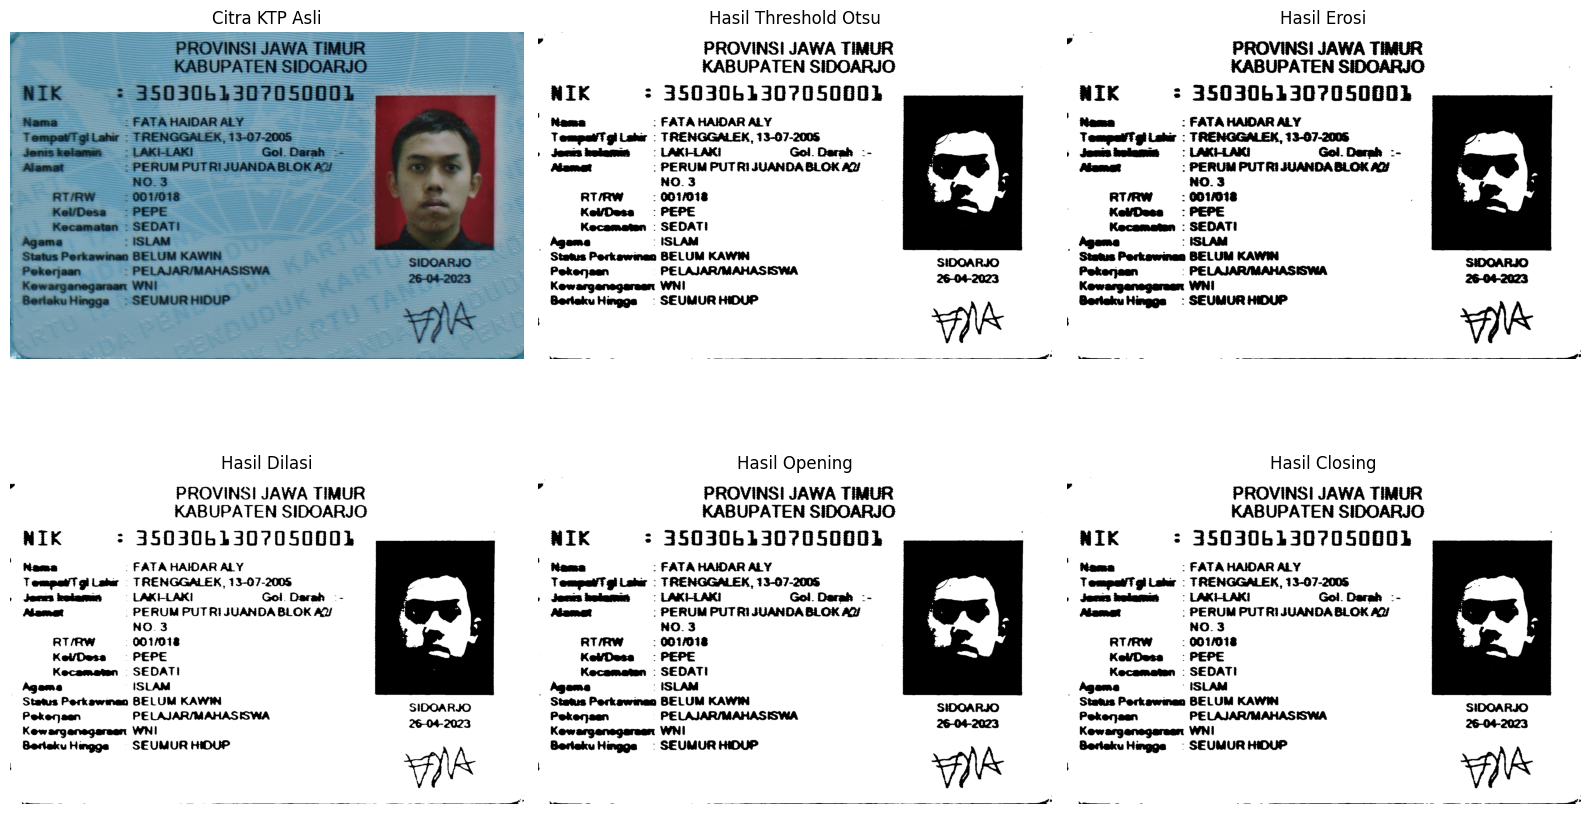


HASIL OCR: Sebelum Morfologi
PROVINSI JAWA TIMUR
KABUPATEN SIDOARJO
NIK : 35030613070509D1
— Nama - FATA HAIDAR ALY
TempatT gi Lah - TRENGGALEK, 13-07-2005 A
| Jemabelamin LAKI-LAKI Gol. Darah --
Alamat : PERUM PUT RI JUANDABLOK AY 1. 3.
NO.3 :
RTRW - 0017018 | as
KeDasa : PEPE —
Kecamatan : SEDATI
. Agama : ISLAM
Status Perkawinan BELUM KAWIN SIDOARJO
Pekerjaan — PELAJAR/MAHASISWA
Kewarganegaraan WNI 26-04-2023
Bertaku Hingga : SEUMUR HIDUP ' |
|


HASIL OCR: Erosi
“1 | PROVINSI JAWA TIMUR
KABUPATEN SIDOARJO |
NIK : 35030613070500D1
— Nama : FATA HAIDAR ALY
TempatiT gi Lahir : TRENGGALEK, 13-07-2005 4
 Jemahalaman LAKI-LAKI Gol. Darah :- |
Alamat : PERUM PUTRI JUANDABLOK AD “ .
NO.3 '
RT RW : 0017018
| KeliDasa : PEPE —
Kecamatan : SEDATI
. #guma : ISLAM
Status Perkawinan BELUM KAWMN
Kewargenegaraan WN!
Berlaku Hingga : SEUMUR HIDUP


HASIL OCR: Dilasi
| PROVINSI JAWA TIMUR
KABUPATEN SIDOARJO
NIK : 3503061307050901 |
Hama - FATA HAIDAR ALY
Tempat Tgl Lah TRENGGALEK, 13-07-2005
| Jeru

In [41]:

# ============================================================
# TUGAS PRAKTIKUM MORFOLOGI - CITRA KTP + OCR
# ============================================================

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pytesseract

# ============================================================
# 1. MEMBACA CITRA KTP
# ============================================================

img = cv.imread('/content/drive/MyDrive/PCVK/ktpku.jpg')

if img is None:
    raise FileNotFoundError("Gambar KTP tidak ditemukan!")

img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# ============================================================
# 2. THRESHOLDING
# ============================================================

blur = cv.GaussianBlur(gray, (5, 5), 0)

nilai_otsu, thresh = cv.threshold(
    blur, 0, 255,
    cv.THRESH_BINARY + cv.THRESH_OTSU
)

# ============================================================
# 3. MEMBUAT STRUCTURING ELEMENT
# ============================================================

kernel = np.ones((3, 3), dtype=np.uint8)

# ============================================================
# 4. OPERASI MORFOLOGI
# ============================================================

# Erosi
erosi = cv.erode(thresh, kernel, iterations=1)

# Dilasi
dilasi = cv.dilate(thresh, kernel, iterations=1)

# Opening
opening = cv.morphologyEx(
    thresh, cv.MORPH_OPEN, kernel
)

# Closing
closing = cv.morphologyEx(
    thresh, cv.MORPH_CLOSE, kernel
)

# ============================================================
# 5. OCR SEBELUM DAN SESUDAH MORFOLOGI
# ============================================================

config = '--oem 3 --psm 6'

citra_ocr = {
    'Sebelum Morfologi': thresh,
    'Erosi': erosi,
    'Dilasi': dilasi,
    'Opening': opening,
    'Closing': closing
}

hasil_ocr = {}

for nama, gambar in citra_ocr.items():
    teks = pytesseract.image_to_string(
        gambar,
        lang='ind',
        config=config
    )
    hasil_ocr[nama] = teks

# ============================================================
# 6. MENAMPILKAN HASIL CITRA
# ============================================================

plt.figure(figsize=(16, 10))

plt.subplot(231)
plt.imshow(img_rgb)
plt.title('Citra KTP Asli')
plt.axis('off')

plt.subplot(232)
plt.imshow(thresh, cmap='gray')
plt.title('Hasil Threshold Otsu')
plt.axis('off')

plt.subplot(233)
plt.imshow(erosi, cmap='gray')
plt.title('Hasil Erosi')
plt.axis('off')

plt.subplot(234)
plt.imshow(dilasi, cmap='gray')
plt.title('Hasil Dilasi')
plt.axis('off')

plt.subplot(235)
plt.imshow(opening, cmap='gray')
plt.title('Hasil Opening')
plt.axis('off')

plt.subplot(236)
plt.imshow(closing, cmap='gray')
plt.title('Hasil Closing')
plt.axis('off')

plt.tight_layout()
plt.show()

# ============================================================
# 7. MENAMPILKAN HASIL PEMBACAAN TEKS OCR
# ============================================================

for nama, teks in hasil_ocr.items():
    print('\n' + '=' * 50)
    print('HASIL OCR:', nama)
    print('=' * 50)
    print(teks if teks.strip() else 'Tidak ada teks yang terbaca.')

print('\nNilai Threshold Otsu:', nilai_otsu)
